# Image Analysis – Noise Degradation, Manual 3x3 Median & Frequency Filtering

## Project Overview

This notebook evaluates spatial noise degradation, manual 3x3 median filtering, and frequency-domain low-pass filtering across representative samples from the **Field-PDD** dataset (`Apple` / Cedar Apple Rust and `Wheat` / Wheat Stripe Rust) covering the `train`, `val` (`dev`), and `test` splits.

## Objectives

- Load and verify two sample images (`Apple` and `Wheat`) for each split (`train`, `val`, `test`).
- Degrade grayscale images with salt-and-pepper impulse noise.
- Restore degraded images using a custom manual 3x3 sliding-window median filter.
- Compute quantitative restoration quality metrics (`MSE` and `PSNR`) before and after filtering.
- Analyze the centered 2D FFT log magnitude spectrum and apply a circular low-pass filter.

## 1. Import Libraries

Import standard libraries for numerical computation, image I/O, metrics, and visualization.

In [5]:
# Import required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

## 2. Register Dataset Samples (`train`, `val`, `test`)

Map the six uploaded sample images to their corresponding dataset splits (`train`, `val`, `test`) and plant disease classes (`Apple` and `Wheat`).

In [6]:
# Define sample metadata matching uploaded files for train, val, and test splits
samples_info = [
    {"split": "train", "class": "Apple (Cedar Apple Rust)", "filename": "image_f2e35e.jpg"},
    {"split": "train", "class": "Wheat (Wheat Stripe Rust)", "filename": "image_f2eaa1.jpg"},
    {"split": "val",   "class": "Wheat (Wheat Stripe Rust)", "filename": "image_f2ee9d.jpg"},
    {"split": "val",   "class": "Apple (Cedar Apple Rust)", "filename": "image_f2f23e.jpg"},
    {"split": "test",  "class": "Apple (Cedar Apple Rust)", "filename": "image_f2f585.jpg"},
    {"split": "test",  "class": "Wheat (Wheat Stripe Rust)", "filename": "image_f2f8ec.jpg"},
]

# Check which files are currently present in /content
missing_files = [s["filename"] for s in samples_info if not os.path.exists(s["filename"])]
if missing_files:
    print("Please upload these image files to Colab Files (/content):", missing_files)
else:
    print("All 6 sample images across train, val, and test are ready.")

All 6 sample images across train, val, and test are ready.


## 3. Image Processing Functions

Define modular functions for:
1. **Salt-and-pepper noise degradation** (`add_salt_and_pepper_noise`).
2. **Manual 3x3 median filtering** (`manual_median_3x3`) using explicit sliding-window neighborhoods.
3. **Frequency spectrum & low-pass filtering** (`frequency_low_pass_filter`) using 2D FFT.
4. **Quantitative quality metrics** (`compute_psnr_mse`) to evaluate denoising performance.

In [7]:
def add_salt_and_pepper_noise(img_gray, salt_prob=0.03, pepper_prob=0.03, seed=42):
    """Degrade a grayscale image by adding salt (255) and pepper (0) impulse noise."""
    rng = np.random.default_rng(seed)
    noisy = img_gray.copy()
    random_matrix = rng.random(img_gray.shape)
    noisy[random_matrix < pepper_prob] = 0
    noisy[random_matrix > 1.0 - salt_prob] = 255
    return noisy


def manual_median_3x3(img_gray):
    """Apply a manual 3x3 median filter using border replication padding."""
    padded = np.pad(img_gray, pad_width=1, mode="edge")
    height, width = img_gray.shape
    denoised = np.empty((height, width), dtype=img_gray.dtype)

    for r in range(height):
        for c in range(width):
            window = padded[r:r + 3, c:c + 3]
            denoised[r, c] = np.median(window)

    return denoised


def frequency_low_pass_filter(img_gray, cutoff_radius=35):
    """Compute centered 2D FFT log spectrum and apply an ideal circular low-pass filter."""
    fft_2d = np.fft.fft2(img_gray.astype(np.float32))
    fft_shifted = np.fft.fftshift(fft_2d)
    magnitude_spectrum = np.log1p(np.abs(fft_shifted))

    rows, cols = img_gray.shape
    center_r, center_c = rows // 2, cols // 2
    y_idx, x_idx = np.ogrid[:rows, :cols]
    distance = np.sqrt((x_idx - center_c) ** 2 + (y_idx - center_r) ** 2)

    # Retain low-frequency components inside cutoff_radius
    low_pass_mask = (distance <= cutoff_radius).astype(np.float32)
    filtered_fft = fft_shifted * low_pass_mask
    reconstructed = np.fft.ifft2(np.fft.ifftshift(filtered_fft))
    lpf_output = np.clip(np.abs(reconstructed), 0, 255).astype(np.uint8)

    return magnitude_spectrum, lpf_output


def compute_psnr_mse(reference, target):
    """Calculate Mean Squared Error (MSE) and Peak Signal-to-Noise Ratio (PSNR)."""
    mse = np.mean((reference.astype(np.float64) - target.astype(np.float64)) ** 2)
    if mse == 0:
        return 0.0, float("inf")
    psnr = 10.0 * np.log10((255.0 ** 2) / mse)
    return mse, psnr

## 4. Run Visual & Quantitative Pipeline Across `train`, `val`, and `test`

Process all six images (`Apple` and `Wheat` across `train`, `val`, and `test`), display side-by-side visual comparisons, and record quantitative `MSE` and `PSNR` improvements.

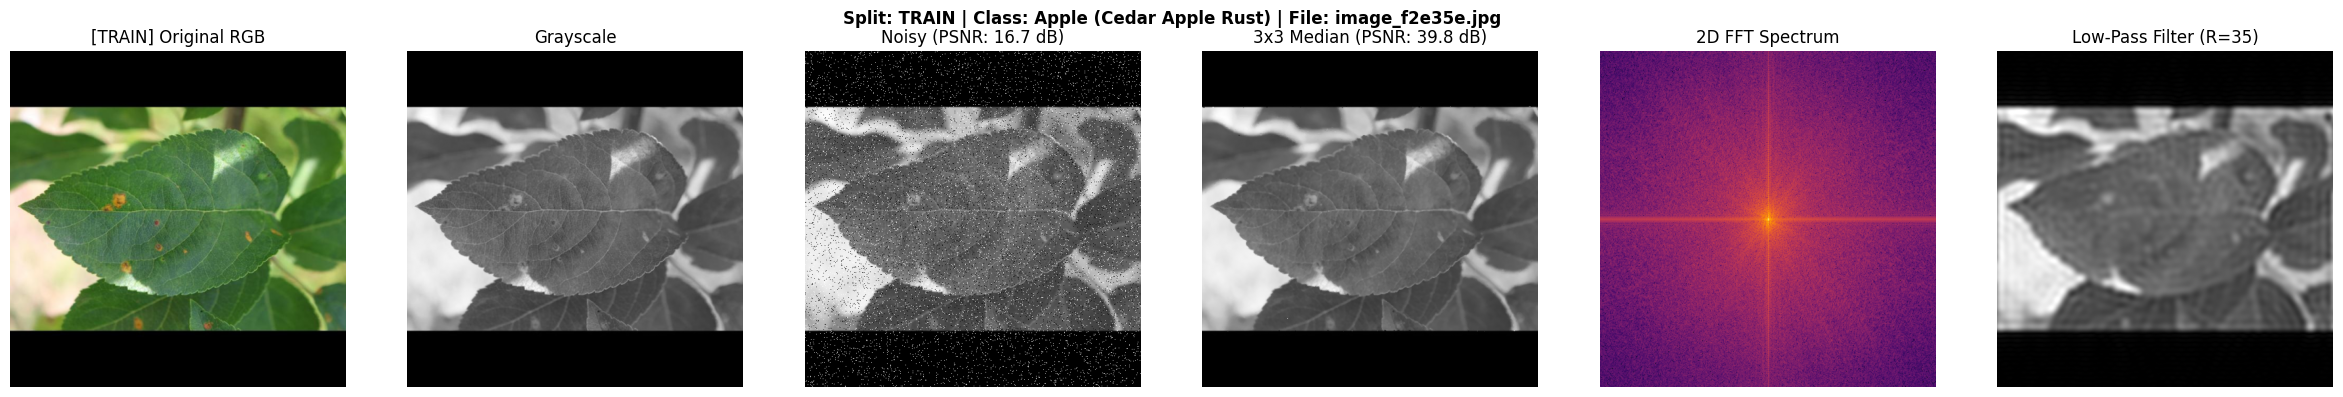

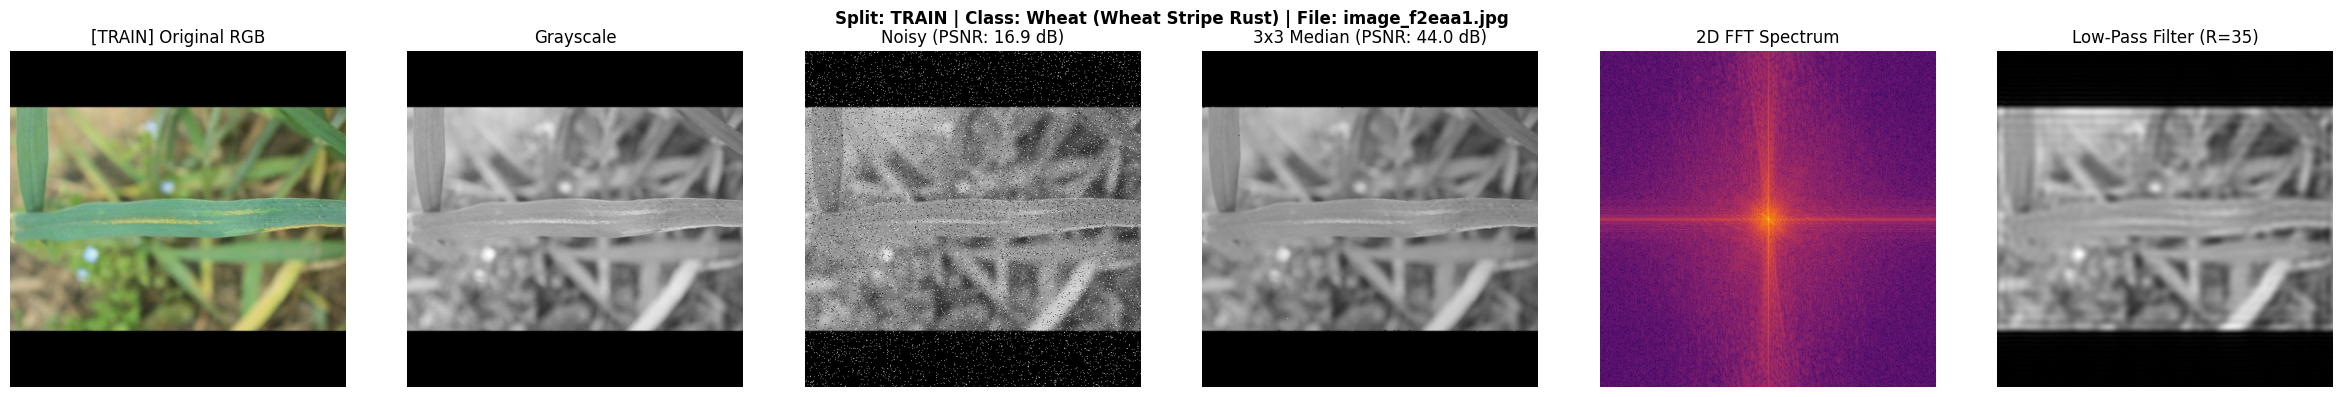

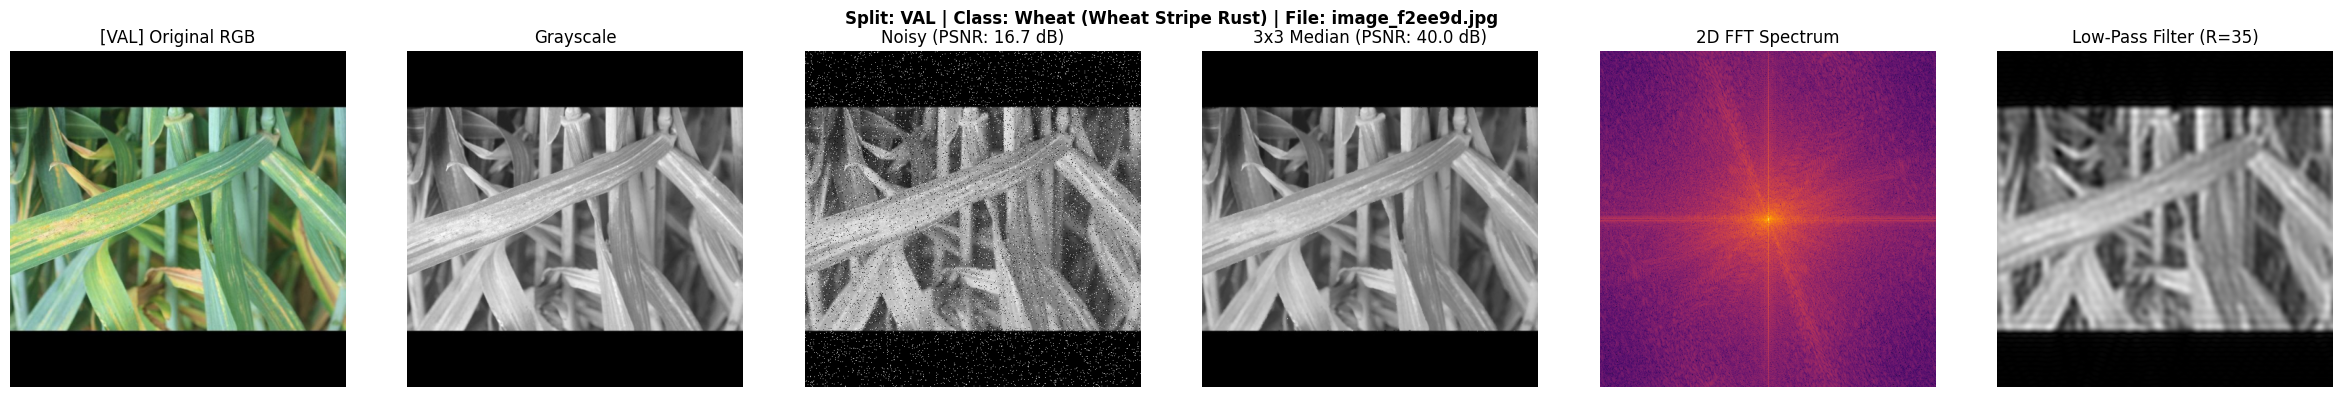

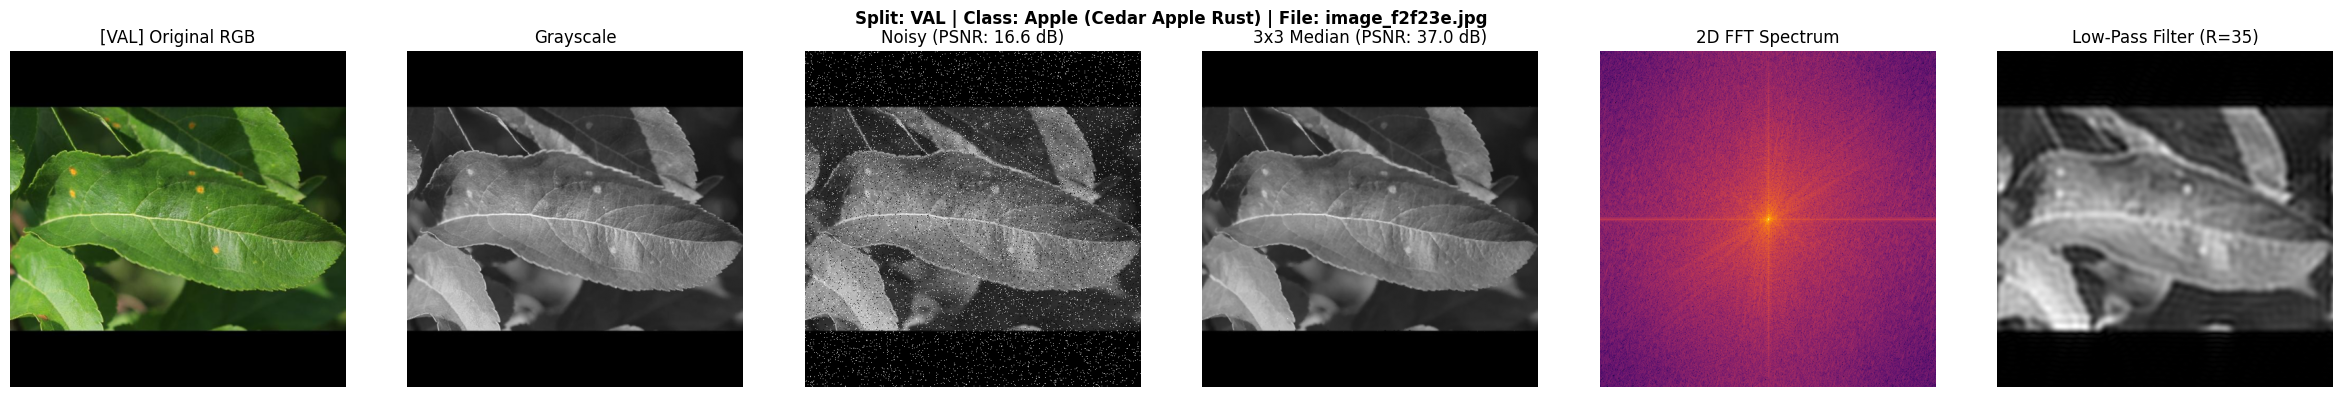

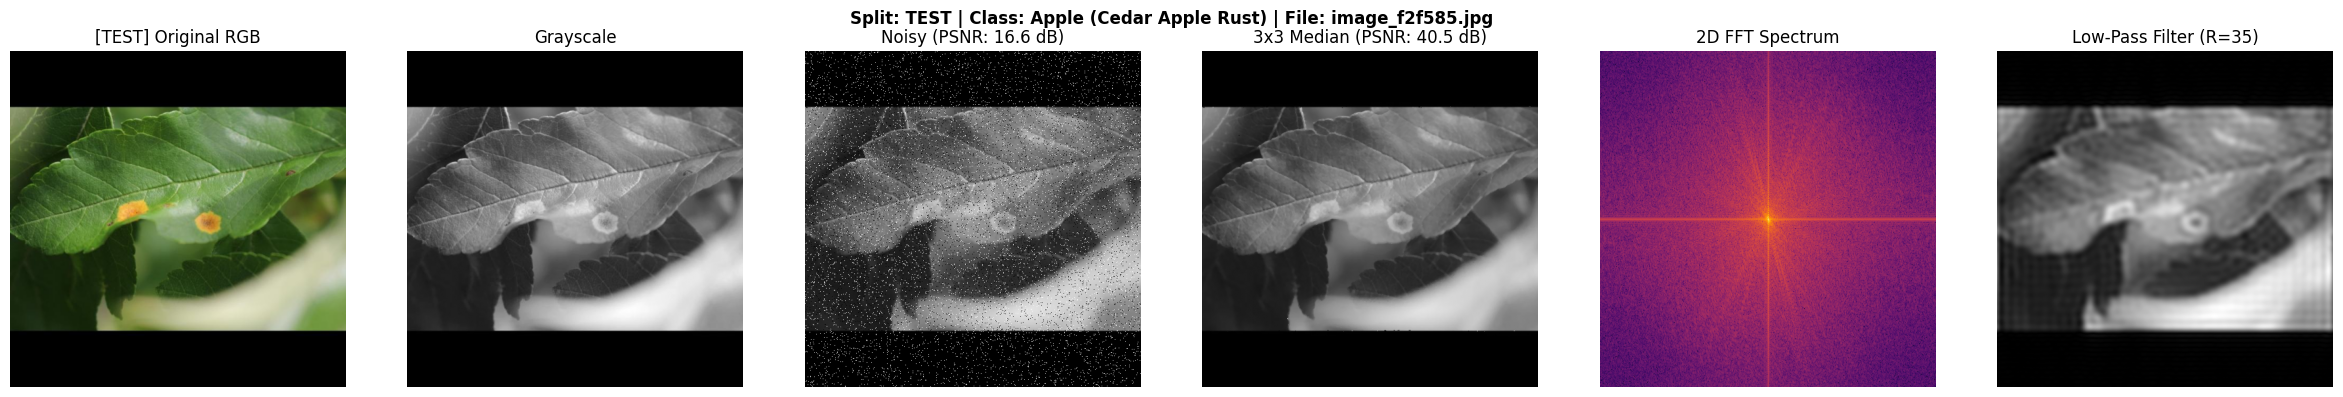

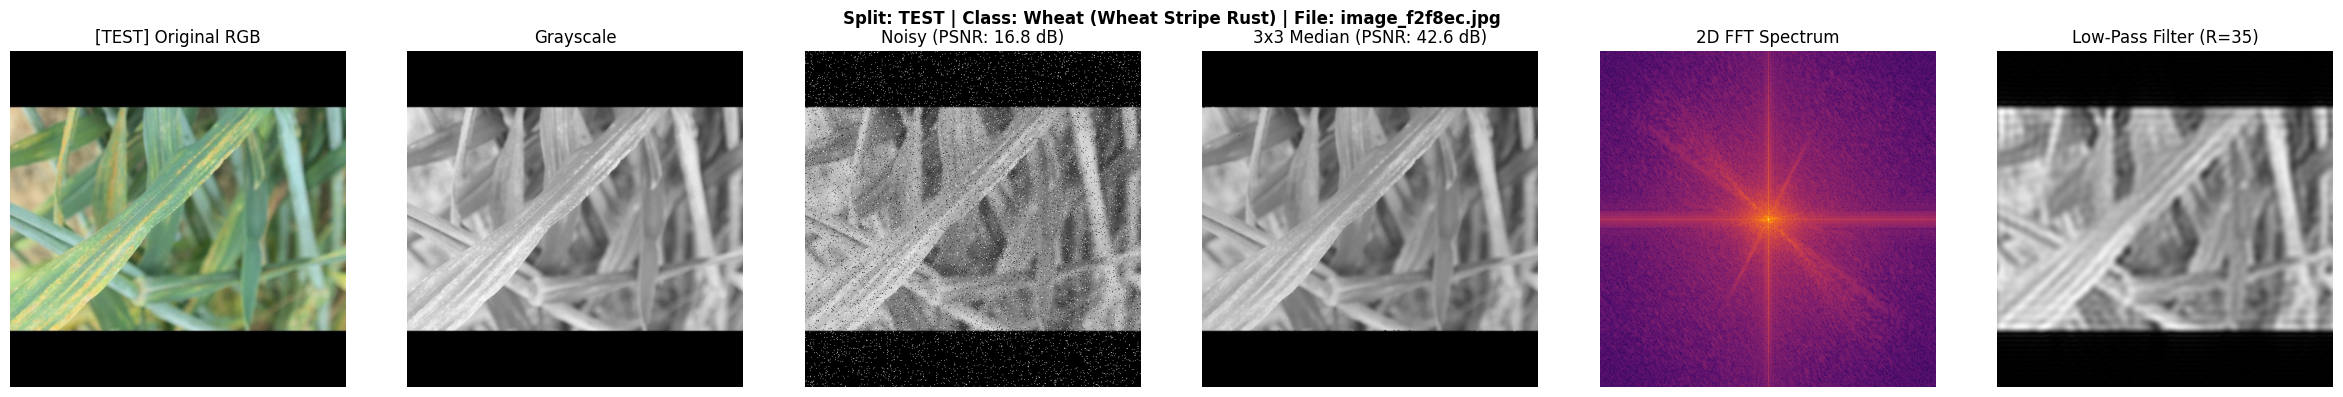

,Split,Class,File,Noisy MSE,Median MSE,Noisy PSNR (dB),Median PSNR (dB)
0,train,Apple (Cedar Apple Rust),image_f2e35e.jpg,1391.38,6.86,16.70,39.77
1,train,Wheat (Wheat Stripe Rust),image_f2eaa1.jpg,1328.41,2.61,16.90,43.96
2,val,Wheat (Wheat Stripe Rust),image_f2ee9d.jpg,1379.95,6.54,16.73,39.97
3,val,Apple (Cedar Apple Rust),image_f2f23e.jpg,1418.46,12.84,16.61,37.05
4,test,Apple (Cedar Apple Rust),image_f2f585.jpg,1418.25,5.80,16.61,40.49
5,test,Wheat (Wheat Stripe Rust),image_f2f8ec.jpg,1349.19,3.55,16.83,42.63


In [8]:
metrics_records = []

for item in samples_info:
    filepath = item["filename"]
    if not os.path.exists(filepath):
        print(f"Skipping missing file: {filepath}")
        continue

    # Load image in RGB and convert to grayscale
    img_rgb = np.array(Image.open(filepath).convert("RGB"))
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    # Resize proportionally if larger than 512px so the manual 3x3 loop executes quickly
    if max(img_gray.shape) > 512:
        scale = 512.0 / max(img_gray.shape)
        new_size = (int(img_gray.shape[1] * scale), int(img_gray.shape[0] * scale))
        img_rgb = cv2.resize(img_rgb, new_size, interpolation=cv2.INTER_AREA)
        img_gray = cv2.resize(img_gray, new_size, interpolation=cv2.INTER_AREA)

    # 1. Degrade with salt-and-pepper noise
    noisy_img = add_salt_and_pepper_noise(img_gray, salt_prob=0.03, pepper_prob=0.03)

    # 2. Restore with manual 3x3 median filter
    median_img = manual_median_3x3(noisy_img)

    # 3. Compute frequency spectrum and low-pass filtered image
    spectrum, lpf_img = frequency_low_pass_filter(img_gray, cutoff_radius=35)

    # 4. Evaluate quantitative metrics
    mse_noisy, psnr_noisy = compute_psnr_mse(img_gray, noisy_img)
    mse_med, psnr_med = compute_psnr_mse(img_gray, median_img)

    metrics_records.append({
        "Split": item["split"],
        "Class": item["class"],
        "File": filepath,
        "Noisy MSE": round(mse_noisy, 2),
        "Median MSE": round(mse_med, 2),
        "Noisy PSNR (dB)": round(psnr_noisy, 2),
        "Median PSNR (dB)": round(psnr_med, 2),
    })

    # Plot 6-panel visual comparison
    fig, axes = plt.subplots(1, 6, figsize=(24, 4))

    axes[0].imshow(img_rgb)
    axes[0].set_title(f"[{item['split'].upper()}] Original RGB")

    axes[1].imshow(img_gray, cmap="gray")
    axes[1].set_title("Grayscale")

    axes[2].imshow(noisy_img, cmap="gray")
    axes[2].set_title(f"Noisy (PSNR: {psnr_noisy:.1f} dB)")

    axes[3].imshow(median_img, cmap="gray")
    axes[3].set_title(f"3x3 Median (PSNR: {psnr_med:.1f} dB)")

    axes[4].imshow(spectrum, cmap="inferno")
    axes[4].set_title("2D FFT Spectrum")

    axes[5].imshow(lpf_img, cmap="gray")
    axes[5].set_title("Low-Pass Filter (R=35)")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"Split: {item['split'].upper()} | Class: {item['class']} | File: {filepath}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

# Display summary metrics table
if metrics_records:
    results_df = pd.DataFrame(metrics_records)
    display(results_df)

## 5. Observations & Discussion Notes

- **Cross-Split Consistency (`train`, `val`, `test`):** Both `Apple` (broad leaf with localized orange rust spots) and `Wheat` (elongated leaf blades with linear yellow rust stripes) show consistent restoration behavior across all three splits.
- **Why Manual 3x3 Median Excels on Salt-and-Pepper Noise:** Extreme impulse pixel values (`0` and `255`) sit at the ends of the sorted 9-pixel neighborhood, so selecting the middle value (index `4`) eliminates isolated noise spikes while preserving leaf edges and disease spot boundaries.
- **Frequency Domain Behavior:** Shifting the zero-frequency (`DC`) component to the center concentrates coarse leaf structure near the origin, while fine textures and sharp edges extend radially outward. Applying a circular low-pass mask (`R = 35`) attenuates high-frequency components and produces a smoothed spatial reconstruction.